In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from IPython.display import display

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

df = pd.read_csv("global_ecommerce_sales.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset Shape: (2000, 15)


,Order_ID,Order_Date,Customer_Name,Customer_Segment,Country,Region,Product_Category,Product_Name,Quantity,Unit_Price,Discount_Percent,Total_Sales,Shipping_Cost,Profit,Payment_Method
0,ORD-11121,2023-01-02,Karen Suzuki,Corporate,United States,North America,Technology,Wireless Bluetooth Headphones,3,99.43,0,298.29,9.31,124.92,Cash on Delivery
1,ORD-11244,2023-01-02,John Johansson,Corporate,Spain,Europe,Technology,Mechanical Gaming Keyboard,4,97.93,20,313.38,14.31,83.62,Cash on Delivery
2,ORD-10325,2023-01-03,Jessica Garcia,Consumer,Mexico,North America,Office Supplies,Binder Clips Assorted 48pc,2,10.74,0,21.48,8.12,3.69,Credit Card
3,ORD-10467,2023-01-03,Clara Taylor,Corporate,Italy,Europe,Technology,Webcam HD 1080p,2,61.86,15,105.16,10.79,26.32,PayPal
4,ORD-11454,2023-01-05,Felix Thomas,Consumer,Italy,Europe,Furniture,Standing Desk Converter,4,330.67,20,"1,058.14",11.09,253.44,Credit Card


In [4]:
# 3. DATA OVERVIEW
# ============================================================

print("\n" + "="*60)
print("DATASET INFORMATION")
print("="*60)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nBasic Statistics:")
display(df.describe())


DATASET INFORMATION

Column Names:
['Order_ID', 'Order_Date', 'Customer_Name', 'Customer_Segment', 'Country', 'Region', 'Product_Category', 'Product_Name', 'Quantity', 'Unit_Price', 'Discount_Percent', 'Total_Sales', 'Shipping_Cost', 'Profit', 'Payment_Method']

Data Types:
Order_ID             object
Order_Date           object
Customer_Name        object
Customer_Segment     object
Country              object
Region               object
Product_Category     object
Product_Name         object
Quantity              int64
Unit_Price          float64
Discount_Percent      int64
Total_Sales         float64
Shipping_Cost       float64
Profit              float64
Payment_Method       object
dtype: object

Missing Values:
Order_ID            0
Order_Date          0
Customer_Name       0
Customer_Segment    0
Country             0
Region              0
Product_Category    0
Product_Name        0
Quantity            0
Unit_Price          0
Discount_Percent    0
Total_Sales         0
Shipping_

,Quantity,Unit_Price,Discount_Percent,Total_Sales,Shipping_Cost,Profit
count,"2,000.00","2,000.00","2,000.00","2,000.00","2,000.00","2,000.00"
mean,3.56,73.33,8.57,242.28,12.90,79.44
std,2.70,79.31,7.26,382.58,5.22,137.57
min,1.00,3.03,0.00,2.42,5.52,-11.28
25%,2.00,18.76,0.00,41.23,9.46,6.87
50%,3.00,46.42,10.00,113.12,11.84,32.83
75%,5.00,90.25,15.00,266.55,14.92,90.30
max,15.00,472.56,30.00,"3,813.98",40.44,"1,373.63"


In [5]:
# ============================================================
# 4. DATA CLEANING
# ============================================================

# Convert Order_Date into datetime format
df['Order_Date'] = pd.to_datetime(df['Order_Date'])

# Remove accidental duplicate rows if any
df = df.drop_duplicates()

# Create useful time columns
df['Year'] = df['Order_Date'].dt.year
df['Month_Number'] = df['Order_Date'].dt.month
df['Month'] = df['Order_Date'].dt.to_period('M').astype(str)

print("\nData cleaning completed.")

print("\nOrder Date Range:")
print("Start Date:", df['Order_Date'].min())
print("End Date:", df['Order_Date'].max())



Data cleaning completed.

Order Date Range:
Start Date: 2023-01-02 00:00:00
End Date: 2025-12-31 00:00:00


In [6]:
# ============================================================
# 5. CATEGORY / SEGMENT / REGION CHECK
# ============================================================

print("\nCustomer Segments:")
print(df['Customer_Segment'].unique())

print("\nRegions:")
print(df['Region'].unique())

print("\nProduct Categories:")
print(df['Product_Category'].unique())

print("\nPayment Methods:")
print(df['Payment_Method'].unique())



Customer Segments:
['Corporate' 'Consumer' 'Home Office']

Regions:
['North America' 'Europe' 'Middle East & Africa' 'Asia Pacific'
 'South America']

Product Categories:
['Technology' 'Office Supplies' 'Furniture' 'Clothing & Accessories']

Payment Methods:
['Cash on Delivery' 'Credit Card' 'PayPal' 'Bank Transfer']


In [7]:
# ============================================================
# 6. KEY PERFORMANCE INDICATORS (KPIs)
# ============================================================

total_sales = df['Total_Sales'].sum()
total_profit = df['Profit'].sum()
total_orders = df['Order_ID'].nunique()
total_quantity = df['Quantity'].sum()
total_customers = df['Customer_Name'].nunique()

average_order_value = total_sales / total_orders
profit_margin = (total_profit / total_sales) * 100
average_discount = df['Discount_Percent'].mean()
total_shipping_cost = df['Shipping_Cost'].sum()

print("\n" + "="*60)
print("KEY PERFORMANCE INDICATORS")
print("="*60)

print(f"Total Sales          : {total_sales:,.2f}")
print(f"Total Profit         : {total_profit:,.2f}")
print(f"Total Orders         : {total_orders:,}")
print(f"Total Customers      : {total_customers:,}")
print(f"Total Quantity       : {total_quantity:,}")
print(f"Average Order Value  : {average_order_value:,.2f}")
print(f"Profit Margin        : {profit_margin:.2f}%")
print(f"Average Discount     : {average_discount:.2f}%")
print(f"Total Shipping Cost  : {total_shipping_cost:,.2f}")



KEY PERFORMANCE INDICATORS
Total Sales          : 484,559.34
Total Profit         : 158,872.32
Total Orders         : 2,000
Total Customers      : 1,534
Total Quantity       : 7,115
Average Order Value  : 242.28
Profit Margin        : 32.79%
Average Discount     : 8.57%
Total Shipping Cost  : 25,804.24


,Month,Total_Sales,Total_Profit,Total_Orders
0,2023-01,"11,275.20","3,573.01",47
1,2023-02,"16,943.67","5,980.06",52
2,2023-03,"16,056.45","5,718.77",51
3,2023-04,"12,185.00","3,994.25",48
4,2023-05,"8,218.47","2,591.86",40


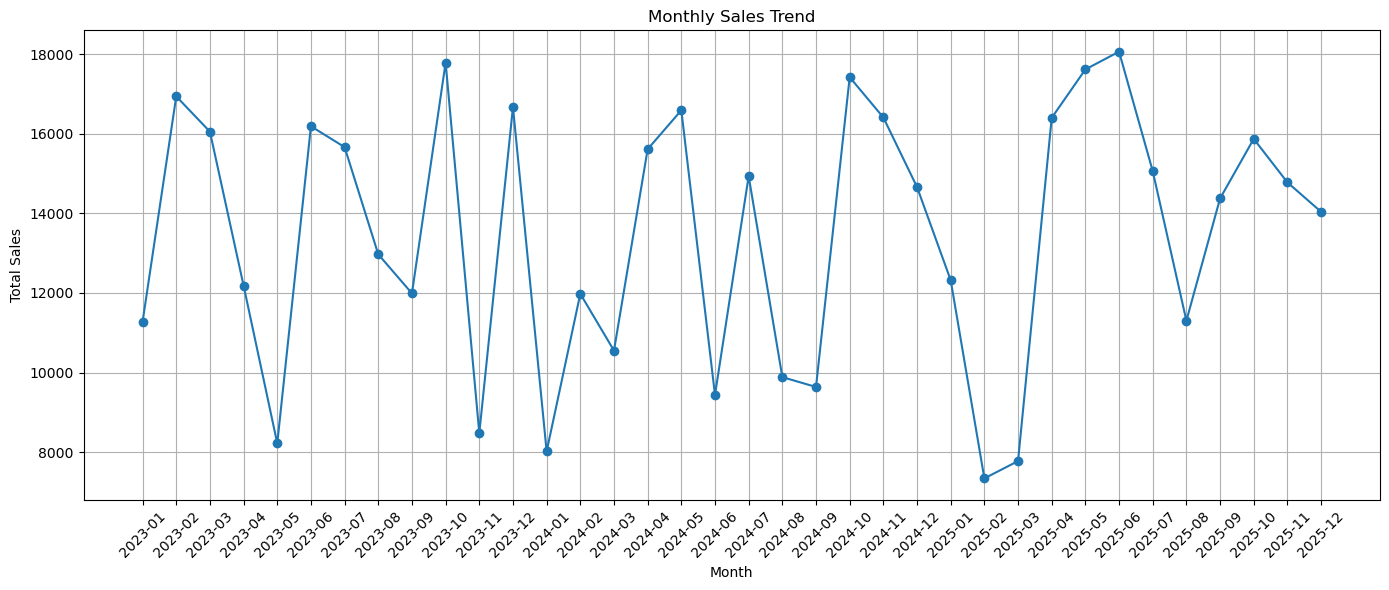

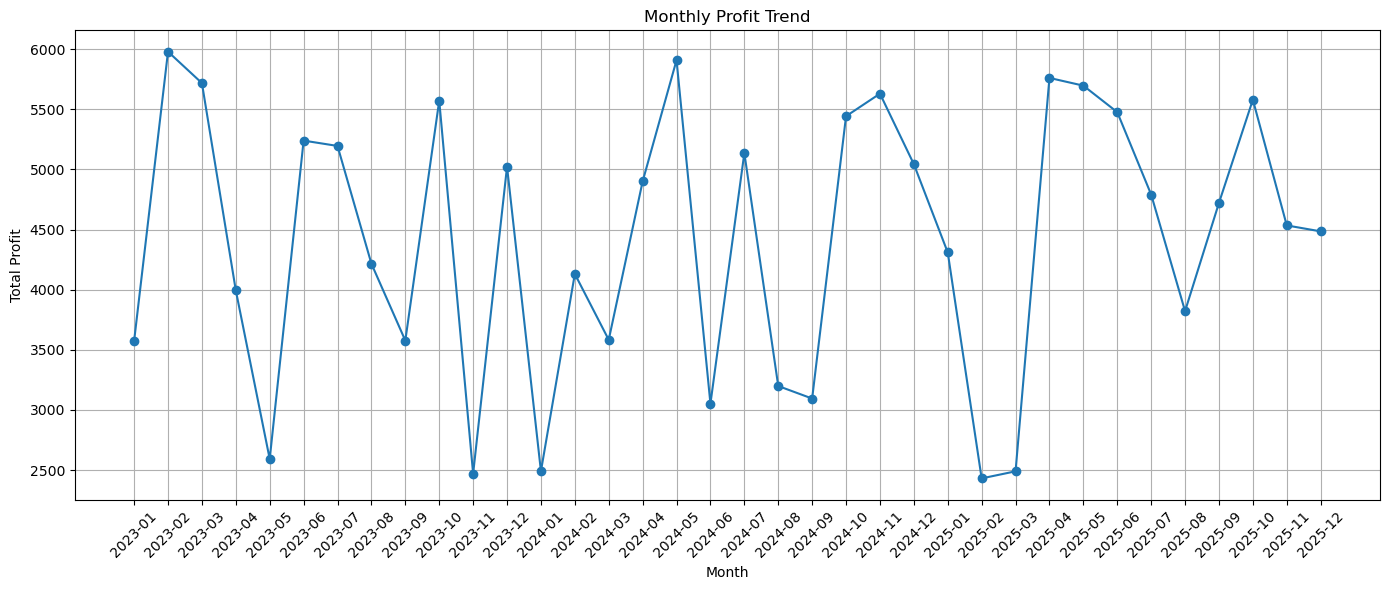

In [8]:
# ============================================================
# 7. MONTHLY SALES & PROFIT ANALYSIS
# ============================================================

monthly_performance = df.groupby('Month').agg(
    Total_Sales=('Total_Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Total_Orders=('Order_ID', 'nunique')
).reset_index()

display(monthly_performance.head())


# Monthly Sales Trend

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_performance['Month'],
    monthly_performance['Total_Sales'],
    marker='o'
)

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


# Monthly Profit Trend

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_performance['Month'],
    monthly_performance['Total_Profit'],
    marker='o'
)

plt.title('Monthly Profit Trend')
plt.xlabel('Month')
plt.ylabel('Total Profit')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()




Yearly Performance:


,Year,Total_Sales,Total_Profit,Total_Orders,Total_Quantity,Profit_Margin_%
0,2023,"164,443.45","53,153.74",670,2340,32.32
1,2024,"155,150.73","51,616.11",649,2355,33.27
2,2025,"164,965.16","54,102.47",681,2420,32.80


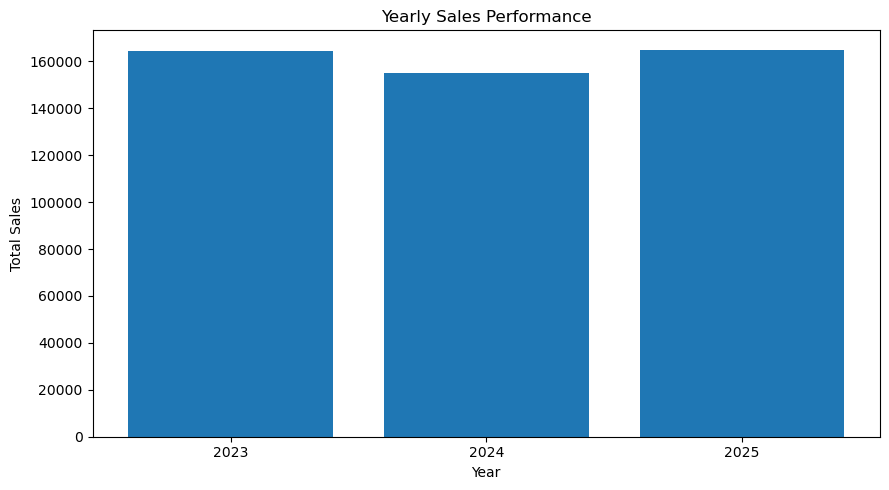

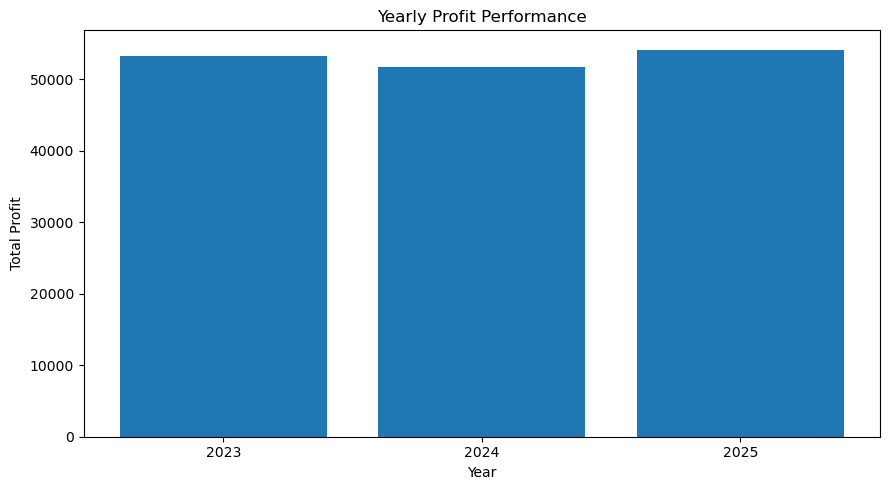

In [9]:
# ============================================================
# 8. YEARLY PERFORMANCE
# ============================================================

yearly_performance = df.groupby('Year').agg(
    Total_Sales=('Total_Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Total_Orders=('Order_ID', 'nunique'),
    Total_Quantity=('Quantity', 'sum')
).reset_index()

yearly_performance['Profit_Margin_%'] = (
    yearly_performance['Total_Profit']
    / yearly_performance['Total_Sales']
) * 100

print("\nYearly Performance:")
display(yearly_performance)


# Yearly Sales

plt.figure(figsize=(9, 5))

plt.bar(
    yearly_performance['Year'].astype(str),
    yearly_performance['Total_Sales']
)

plt.title('Yearly Sales Performance')
plt.xlabel('Year')
plt.ylabel('Total Sales')
plt.tight_layout()
plt.show()


# Yearly Profit

plt.figure(figsize=(9, 5))

plt.bar(
    yearly_performance['Year'].astype(str),
    yearly_performance['Total_Profit']
)

plt.title('Yearly Profit Performance')
plt.xlabel('Year')
plt.ylabel('Total Profit')
plt.tight_layout()
plt.show()



PRODUCT CATEGORY PERFORMANCE


,Product_Category,Total_Sales,Total_Profit,Total_Quantity,Number_of_Orders,Profit_Margin_%
1,Furniture,"256,274.68","81,171.57",1806,507,31.67
3,Technology,"139,518.22","48,268.65",2017,567,34.60
0,Clothing & Accessories,"69,375.63","26,112.94",1551,413,37.64
2,Office Supplies,"19,390.81","3,319.16",1741,513,17.12


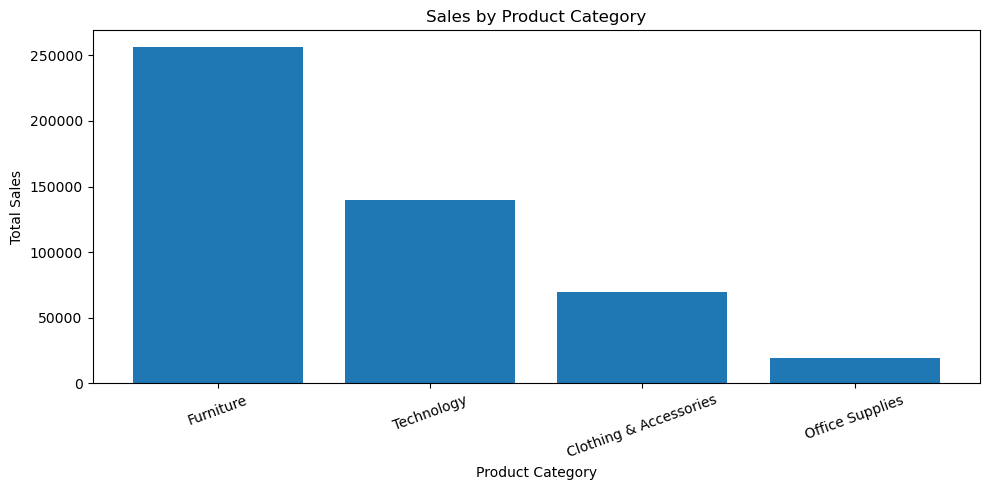

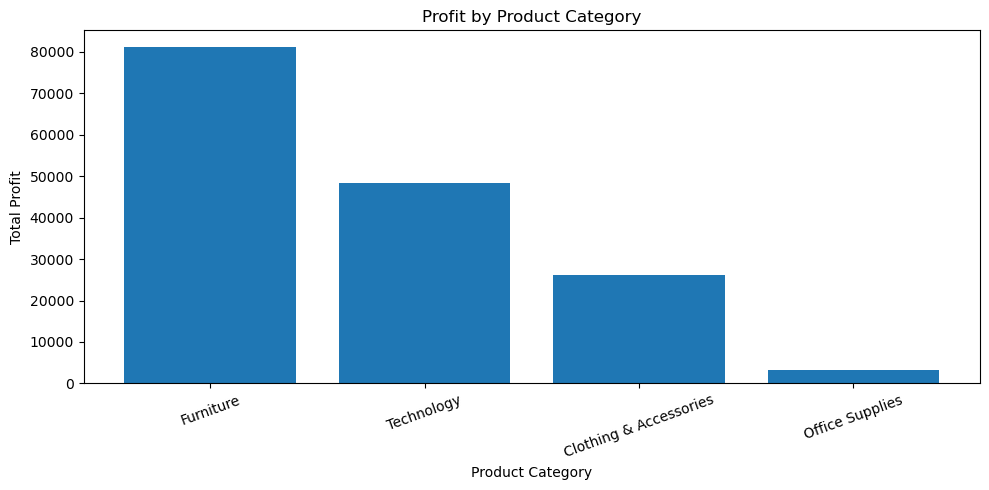

In [10]:
# ============================================================
# 9. PRODUCT CATEGORY ANALYSIS
# ============================================================

category_performance = df.groupby('Product_Category').agg(
    Total_Sales=('Total_Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Total_Quantity=('Quantity', 'sum'),
    Number_of_Orders=('Order_ID', 'nunique')
).reset_index()

category_performance['Profit_Margin_%'] = (
    category_performance['Total_Profit']
    / category_performance['Total_Sales']
) * 100

category_performance = category_performance.sort_values(
    by='Total_Sales',
    ascending=False
)

print("\n" + "="*60)
print("PRODUCT CATEGORY PERFORMANCE")
print("="*60)

display(category_performance)


# Category Sales

plt.figure(figsize=(10, 5))

plt.bar(
    category_performance['Product_Category'],
    category_performance['Total_Sales']
)

plt.title('Sales by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


# Category Profit

plt.figure(figsize=(10, 5))

plt.bar(
    category_performance['Product_Category'],
    category_performance['Total_Profit']
)

plt.title('Profit by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Profit')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()





CUSTOMER SEGMENT PERFORMANCE


,Customer_Segment,Total_Sales,Total_Profit,Total_Quantity,Number_of_Orders,Number_of_Customers,Profit_Margin_%
0,Consumer,"256,287.74","87,300.36",3602,1006,864,34.06
1,Corporate,"146,050.39","44,463.44",2195,623,558,30.44
2,Home Office,"82,221.21","27,108.52",1318,371,355,32.97


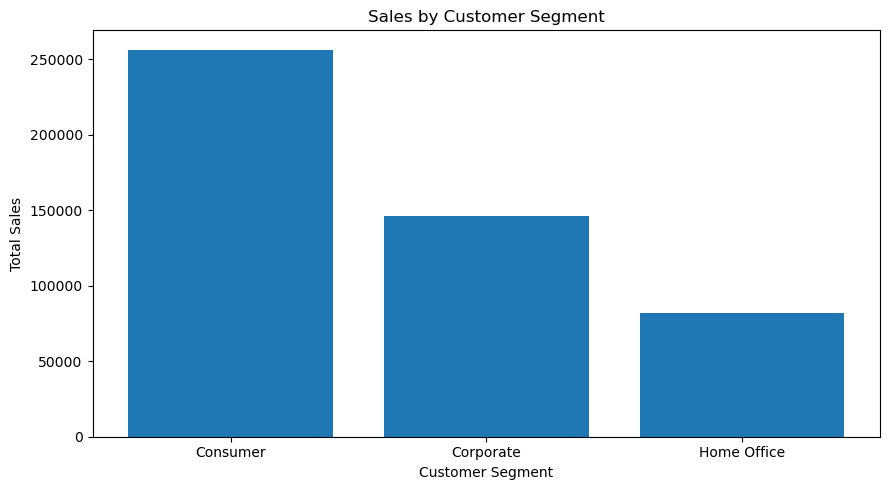

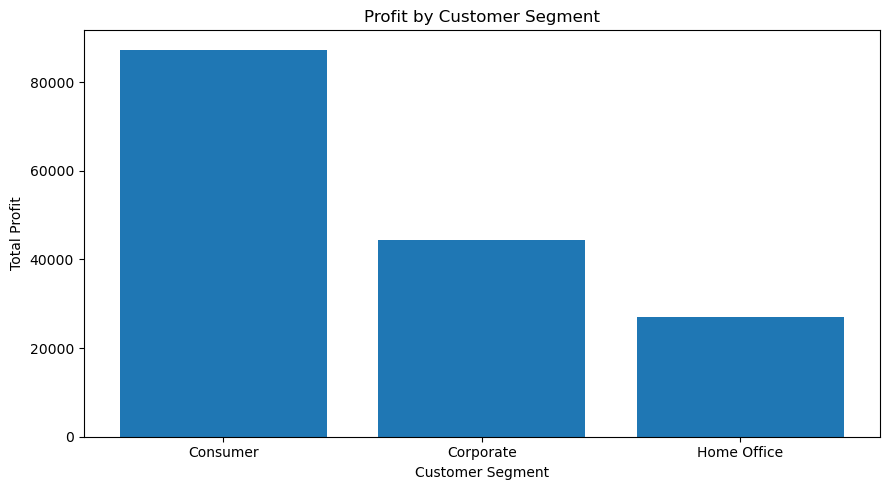

In [11]:
# ============================================================
# 10. CUSTOMER SEGMENT ANALYSIS
# ============================================================

segment_performance = df.groupby('Customer_Segment').agg(
    Total_Sales=('Total_Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Total_Quantity=('Quantity', 'sum'),
    Number_of_Orders=('Order_ID', 'nunique'),
    Number_of_Customers=('Customer_Name', 'nunique')
).reset_index()

segment_performance['Profit_Margin_%'] = (
    segment_performance['Total_Profit']
    / segment_performance['Total_Sales']
) * 100

segment_performance = segment_performance.sort_values(
    by='Total_Sales',
    ascending=False
)

print("\n" + "="*60)
print("CUSTOMER SEGMENT PERFORMANCE")
print("="*60)

display(segment_performance)


# Segment Sales

plt.figure(figsize=(9, 5))

plt.bar(
    segment_performance['Customer_Segment'],
    segment_performance['Total_Sales']
)

plt.title('Sales by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Total Sales')
plt.tight_layout()
plt.show()


# Segment Profit

plt.figure(figsize=(9, 5))

plt.bar(
    segment_performance['Customer_Segment'],
    segment_performance['Total_Profit']
)

plt.title('Profit by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Total Profit')
plt.tight_layout()
plt.show()




REGIONAL PERFORMANCE


,Region,Total_Sales,Total_Profit,Total_Quantity,Number_of_Orders,Profit_Margin_%
1,Europe,"137,006.20","45,672.16",1822,503,33.34
3,North America,"133,876.38","45,250.09",1996,578,33.80
0,Asia Pacific,"121,707.51","39,116.61",1909,520,32.14
4,South America,"46,051.13","14,680.98",658,191,31.88
2,Middle East & Africa,"45,918.12","14,152.48",730,208,30.82


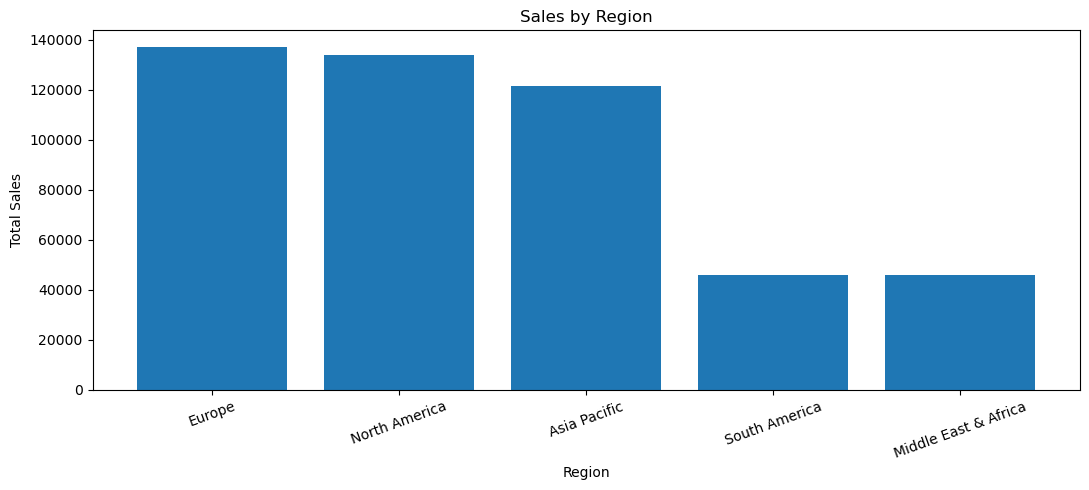

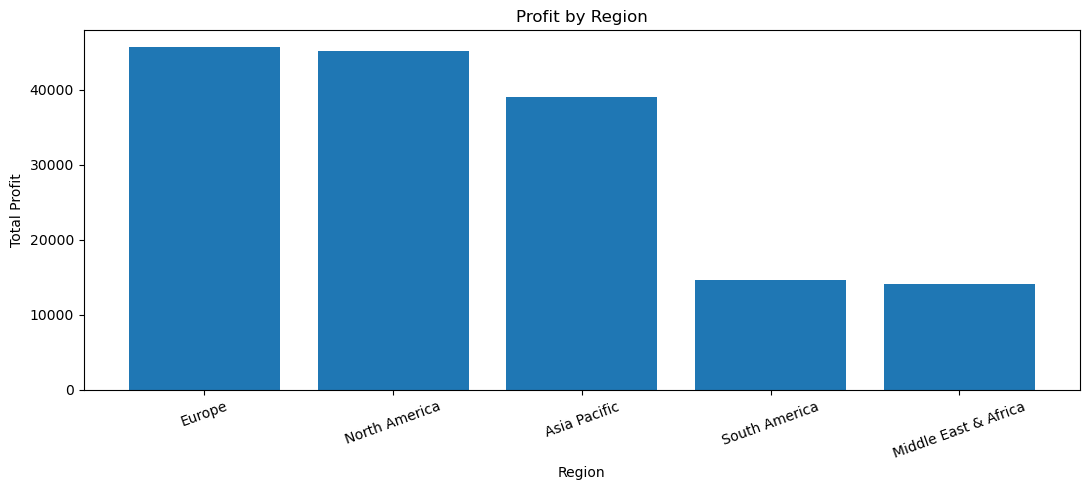

In [13]:
#============================================================
# 11. REGIONAL ANALYSIS
# ============================================================

regional_performance = df.groupby('Region').agg(
    Total_Sales=('Total_Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Total_Quantity=('Quantity', 'sum'),
    Number_of_Orders=('Order_ID', 'nunique')
).reset_index()

regional_performance['Profit_Margin_%'] = (
    regional_performance['Total_Profit']
    / regional_performance['Total_Sales']
) * 100

regional_performance = regional_performance.sort_values(
    by='Total_Sales',
    ascending=False
)

print("\n" + "="*60)
print("REGIONAL PERFORMANCE")
print("="*60)

display(regional_performance)


# Regional Sales

plt.figure(figsize=(11, 5))

plt.bar(
    regional_performance['Region'],
    regional_performance['Total_Sales']
)

plt.title('Sales by Region')
plt.xlabel('Region')
plt.ylabel('Total Sales')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


# Regional Profit

plt.figure(figsize=(11, 5))

plt.bar(
    regional_performance['Region'],
    regional_performance['Total_Profit']
)

plt.title('Profit by Region')
plt.xlabel('Region')
plt.ylabel('Total Profit')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()



In [14]:
# ============================================================
# 12. COUNTRY ANALYSIS
# ============================================================

country_performance = df.groupby('Country').agg(
    Total_Sales=('Total_Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Number_of_Orders=('Order_ID', 'nunique')
).reset_index()

country_performance['Profit_Margin_%'] = (
    country_performance['Total_Profit']
    / country_performance['Total_Sales']
) * 100

country_performance = country_performance.sort_values(
    by='Total_Sales',
    ascending=False
)

print("\nTop 10 Countries by Sales:")
display(country_performance.head(10))


# ============================================================
# 13. TOP PRODUCTS
# ============================================================

product_performance = df.groupby('Product_Name').agg(
    Total_Sales=('Total_Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Total_Quantity=('Quantity', 'sum'),
    Number_of_Orders=('Order_ID', 'nunique')
).reset_index()

product_performance['Profit_Margin_%'] = (
    product_performance['Total_Profit']
    / product_performance['Total_Sales']
) * 100


# Top 10 Products by Sales

top_products_sales = product_performance.sort_values(
    by='Total_Sales',
    ascending=False
).head(10)

print("\n" + "="*60)
print("TOP 10 PRODUCTS BY SALES")
print("="*60)

display(top_products_sales)


# Top 10 Products by Profit

top_products_profit = product_performance.sort_values(
    by='Total_Profit',
    ascending=False
).head(10)

print("\n" + "="*60)
print("TOP 10 PRODUCTS BY PROFIT")
print("="*60)

display(top_products_profit)


Top 10 Countries by Sales:


,Country,Total_Sales,Total_Profit,Number_of_Orders,Profit_Margin_%
11,Mexico,"47,217.30","15,949.44",203,33.78
3,Canada,"45,326.55","15,320.95",179,33.80
19,United States,"41,332.53","13,979.70",196,33.82
10,Japan,"30,950.19","9,826.31",124,31.75
18,United Kingdom,"30,185.46","10,185.32",106,33.74
7,Germany,"28,989.73","9,518.07",95,32.83
4,China,"28,322.85","9,028.07",109,31.88
9,Italy,"27,484.38","9,125.06",105,33.20
6,France,"26,616.81","8,973.46",105,33.71
1,Australia,"25,287.72","8,072.37",107,31.92



TOP 10 PRODUCTS BY SALES


,Product_Name,Total_Sales,Total_Profit,Total_Quantity,Number_of_Orders,Profit_Margin_%
28,Standing Desk Converter,"46,614.22","14,694.35",215,57,31.52
9,Ergonomic Office Chair,"45,405.15","15,104.58",167,42,33.27
5,Corner L-Shaped Desk,"41,070.48","13,663.00",146,39,33.27
18,Mesh Back Task Chair,"38,179.77","12,820.11",213,59,33.58
37,Wireless Bluetooth Headphones,"28,258.70","10,611.08",212,56,37.55
17,Mechanical Gaming Keyboard,"24,072.42","8,381.19",227,58,34.82
10,Filing Cabinet 3-Drawer,"23,108.01","7,041.80",170,45,30.47
12,Folding Table Portable,"18,663.13","5,589.03",226,57,29.95
23,Portable External SSD 1TB,"18,065.30","6,556.75",185,55,36.29
2,Bookshelf 5-Tier,"17,741.59","5,490.57",154,55,30.95



TOP 10 PRODUCTS BY PROFIT


,Product_Name,Total_Sales,Total_Profit,Total_Quantity,Number_of_Orders,Profit_Margin_%
9,Ergonomic Office Chair,"45,405.15","15,104.58",167,42,33.27
28,Standing Desk Converter,"46,614.22","14,694.35",215,57,31.52
5,Corner L-Shaped Desk,"41,070.48","13,663.00",146,39,33.27
18,Mesh Back Task Chair,"38,179.77","12,820.11",213,59,33.58
37,Wireless Bluetooth Headphones,"28,258.70","10,611.08",212,56,37.55
17,Mechanical Gaming Keyboard,"24,072.42","8,381.19",227,58,34.82
10,Filing Cabinet 3-Drawer,"23,108.01","7,041.80",170,45,30.47
23,Portable External SSD 1TB,"18,065.30","6,556.75",185,55,36.29
3,Business Casual Blazer,"14,327.72","6,004.33",160,40,41.91
20,Noise Cancelling Earbuds,"16,119.60","5,973.01",138,48,37.05



LOSS-MAKING ORDERS
Number of loss-making orders: 272
Total loss: -953.39


,Order_ID,Order_Date,Customer_Name,Product_Category,Product_Name,Discount_Percent,Total_Sales,Shipping_Cost,Profit
314,ORD-10024,2023-07-09,Giulia Dubois,Office Supplies,Paper Clips Box 500pc,0,6.62,14.92,-11.28
1179,ORD-11269,2024-10-17,Sophie Johansson,Office Supplies,Paper Clips Box 500pc,15,4.14,12.43,-10.48
1387,ORD-11001,2025-02-20,Isabella Jackson,Office Supplies,Paper Clips Box 500pc,20,2.42,11.16,-10.10
53,ORD-11430,2023-02-04,Karen Martinez,Office Supplies,Paper Clips Box 500pc,10,4.30,11.84,-9.69
1544,ORD-11873,2025-05-11,Susan Garcia,Office Supplies,Whiteboard Markers Set 8,10,6.24,12.29,-9.17
...,...,...,...,...,...,...,...,...,...
692,ORD-10672,2024-01-14,Thomas Miller,Office Supplies,Binder Clips Assorted 48pc,15,28.36,13.43,-0.08
368,ORD-10842,2023-08-06,Hans Anderson,Clothing & Accessories,Canvas Messenger Bag,15,29.04,12.01,-0.06
1439,ORD-11862,2025-03-26,Thomas Clark,Furniture,Desk Organizer Set,20,46.70,11.71,-0.04
1908,ORD-10682,2025-11-17,Clara Fischer,Office Supplies,Desk Calendar 2025,5,22.80,12.01,-0.01



DISCOUNT ANALYSIS


,Discount_Percent,Total_Sales,Total_Profit,Number_of_Orders,Profit_Margin_%
0,0,"130,966.22","50,705.28",503,38.72
1,5,"130,452.23","46,129.15",488,35.36
2,10,"103,136.11","32,932.51",443,31.93
3,15,"61,074.44","16,503.10",312,27.02
4,20,"40,229.76","9,305.38",169,23.13
5,25,"13,272.27","2,568.58",67,19.35
6,30,"5,428.31",728.32,18,13.42


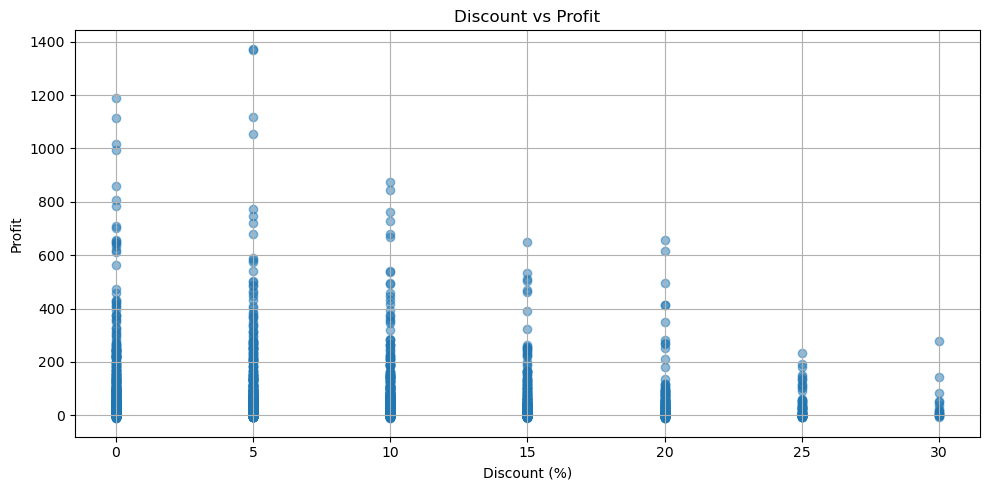

In [15]:
# ============================================================
# 14. LOSS-MAKING ORDERS
# ============================================================

loss_orders = df[df['Profit'] < 0].copy()

print("\n" + "="*60)
print("LOSS-MAKING ORDERS")
print("="*60)

print("Number of loss-making orders:", len(loss_orders))
print("Total loss:", loss_orders['Profit'].sum())

display(
    loss_orders[
        [
            'Order_ID',
            'Order_Date',
            'Customer_Name',
            'Product_Category',
            'Product_Name',
            'Discount_Percent',
            'Total_Sales',
            'Shipping_Cost',
            'Profit'
        ]
    ].sort_values(by='Profit')
)


# ============================================================
# 15. DISCOUNT ANALYSIS
# ============================================================

discount_analysis = df.groupby('Discount_Percent').agg(
    Total_Sales=('Total_Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Number_of_Orders=('Order_ID', 'nunique')
).reset_index()

discount_analysis['Profit_Margin_%'] = (
    discount_analysis['Total_Profit']
    / discount_analysis['Total_Sales']
) * 100

print("\n" + "="*60)
print("DISCOUNT ANALYSIS")
print("="*60)

display(discount_analysis)


# Discount vs Profit

plt.figure(figsize=(10, 5))

plt.scatter(
    df['Discount_Percent'],
    df['Profit'],
    alpha=0.5
)

plt.title('Discount vs Profit')
plt.xlabel('Discount (%)')
plt.ylabel('Profit')
plt.grid(True)
plt.tight_layout()
plt.show()



SHIPPING COST ANALYSIS


,Product_Category,Average_Shipping_Cost,Total_Shipping_Cost,Total_Profit
0,Clothing & Accessories,12.93,"5,340.86","26,112.94"
1,Furniture,13.00,"6,590.57","81,171.57"
2,Office Supplies,12.67,"6,500.86","3,319.16"
3,Technology,13.00,"7,371.95","48,268.65"



PAYMENT METHOD PERFORMANCE


,Payment_Method,Total_Sales,Total_Profit,Number_of_Orders,Profit_Margin_%
2,Credit Card,"192,717.89","62,323.24",797,32.34
3,PayPal,"143,112.87","47,288.80",609,33.04
1,Cash on Delivery,"77,129.54","25,704.89",301,33.33
0,Bank Transfer,"71,599.04","23,555.39",293,32.90


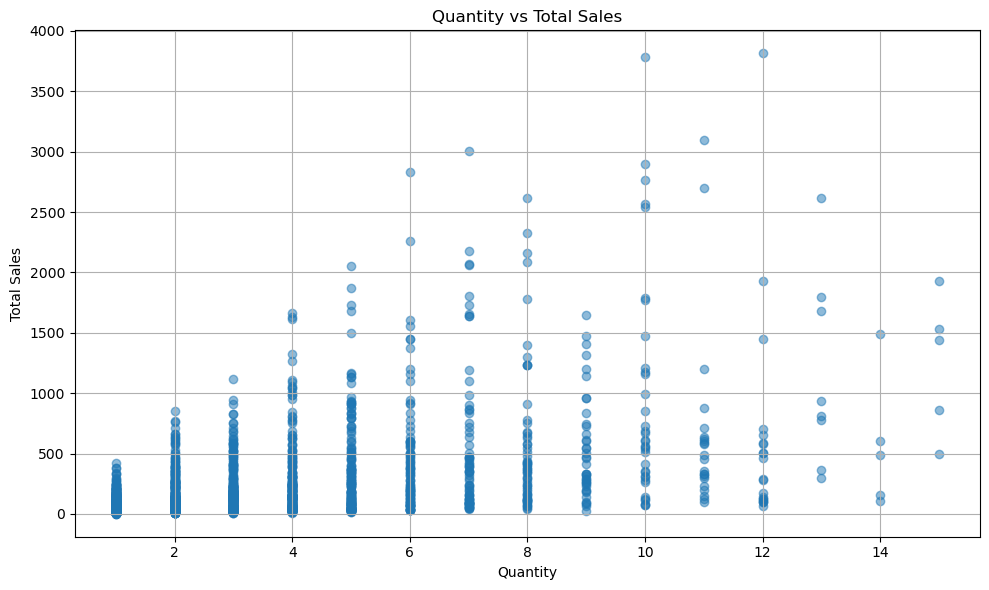

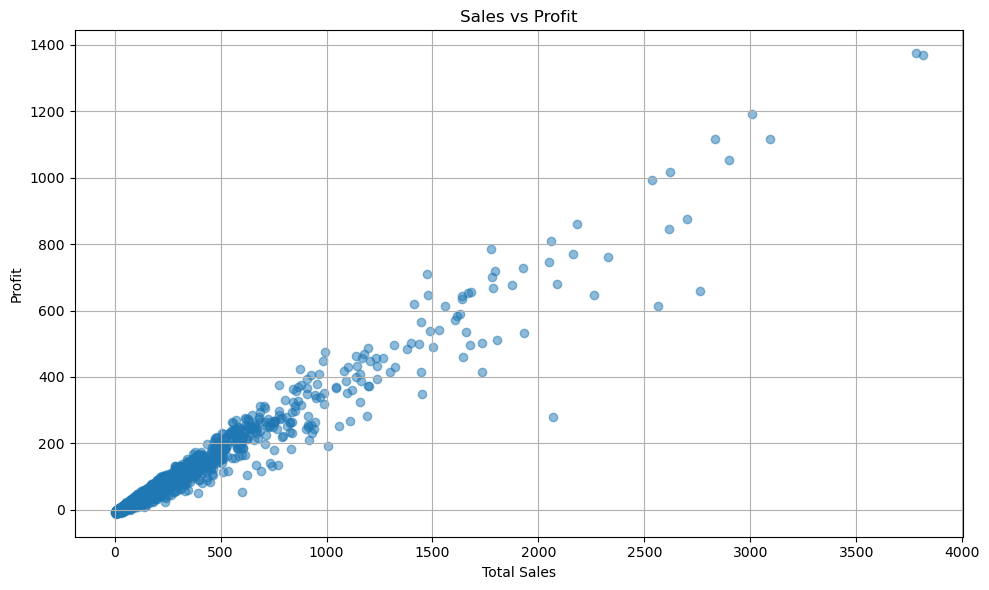


CORRELATION MATRIX


,Quantity,Unit_Price,Discount_Percent,Total_Sales,Shipping_Cost,Profit
Quantity,1.00,0.02,0.01,0.50,0.77,0.50
Unit_Price,0.02,1.00,0.02,0.70,0.02,0.67
Discount_Percent,0.01,0.02,1.00,-0.05,0.02,-0.14
Total_Sales,0.50,0.70,-0.05,1.00,0.39,0.98
Shipping_Cost,0.77,0.02,0.02,0.39,1.00,0.36
Profit,0.50,0.67,-0.14,0.98,0.36,1.00



BUSINESS INTELLIGENCE SUMMARY

1. Overall Performance:
   Total Sales = 484,559.34
   Total Profit = 158,872.32
   Profit Margin = 32.79%

2. Top Category by Sales:
   Furniture with sales of 256,274.68

3. Top Category by Profit:
   Furniture with profit of 81,171.57

4. Lowest Category by Sales:
   Office Supplies with sales of 19,390.81

5. Top Region by Sales:
   Europe with sales of 137,006.20

6. Lowest Region by Sales:
   Middle East & Africa with sales of 45,918.12

7. Top Customer Segment by Sales:
   Consumer with sales of 256,287.74

8. Lowest Customer Segment by Sales:
   Home Office with sales of 82,221.21

9. Category with Lowest Profit Margin:
   Office Supplies with margin of 17.12%

10. Loss-Making Orders:
   272 orders have negative profit.

BUSINESS RECOMMENDATIONS

1. Focus on high-performing product categories and protect their
   revenue contribution.

2. Investigate categories with low profit margins to understand
   the effect of pricing, discounts and operatin

In [16]:

# ============================================================
# 16. SHIPPING COST ANALYSIS
# ============================================================

shipping_analysis = df.groupby('Product_Category').agg(
    Average_Shipping_Cost=('Shipping_Cost', 'mean'),
    Total_Shipping_Cost=('Shipping_Cost', 'sum'),
    Total_Profit=('Profit', 'sum')
).reset_index()

print("\n" + "="*60)
print("SHIPPING COST ANALYSIS")
print("="*60)

display(shipping_analysis)


# ============================================================
# 17. PAYMENT METHOD ANALYSIS
# ============================================================

payment_performance = df.groupby('Payment_Method').agg(
    Total_Sales=('Total_Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Number_of_Orders=('Order_ID', 'nunique')
).reset_index()

payment_performance['Profit_Margin_%'] = (
    payment_performance['Total_Profit']
    / payment_performance['Total_Sales']
) * 100

payment_performance = payment_performance.sort_values(
    by='Total_Sales',
    ascending=False
)

print("\n" + "="*60)
print("PAYMENT METHOD PERFORMANCE")
print("="*60)

display(payment_performance)


# ============================================================
# 18. QUANTITY VS SALES
# ============================================================

plt.figure(figsize=(10, 6))

plt.scatter(
    df['Quantity'],
    df['Total_Sales'],
    alpha=0.5
)

plt.title('Quantity vs Total Sales')
plt.xlabel('Quantity')
plt.ylabel('Total Sales')
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 19. SALES VS PROFIT
# ============================================================

plt.figure(figsize=(10, 6))

plt.scatter(
    df['Total_Sales'],
    df['Profit'],
    alpha=0.5
)

plt.title('Sales vs Profit')
plt.xlabel('Total Sales')
plt.ylabel('Profit')
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 20. CORRELATION ANALYSIS
# ============================================================

numeric_columns = [
    'Quantity',
    'Unit_Price',
    'Discount_Percent',
    'Total_Sales',
    'Shipping_Cost',
    'Profit'
]

correlation_matrix = df[numeric_columns].corr()

print("\n" + "="*60)
print("CORRELATION MATRIX")
print("="*60)

display(correlation_matrix)


# ============================================================
# 21. BEST & WORST PERFORMERS
# ============================================================

best_category_sales = category_performance.iloc[0]
worst_category_sales = category_performance.iloc[-1]

best_region_sales = regional_performance.iloc[0]
worst_region_sales = regional_performance.iloc[-1]

best_segment_sales = segment_performance.iloc[0]
worst_segment_sales = segment_performance.iloc[-1]

best_category_profit = category_performance.loc[
    category_performance['Total_Profit'].idxmax()
]

worst_category_margin = category_performance.loc[
    category_performance['Profit_Margin_%'].idxmin()
]


# ============================================================
# 22. AUTOMATIC BUSINESS SUMMARY
# ============================================================

print("\n" + "="*60)
print("BUSINESS INTELLIGENCE SUMMARY")
print("="*60)

print(
    f"\n1. Overall Performance:"
    f"\n   Total Sales = {total_sales:,.2f}"
    f"\n   Total Profit = {total_profit:,.2f}"
    f"\n   Profit Margin = {profit_margin:.2f}%"
)

print(
    f"\n2. Top Category by Sales:"
    f"\n   {best_category_sales['Product_Category']}"
    f" with sales of {best_category_sales['Total_Sales']:,.2f}"
)

print(
    f"\n3. Top Category by Profit:"
    f"\n   {best_category_profit['Product_Category']}"
    f" with profit of {best_category_profit['Total_Profit']:,.2f}"
)

print(
    f"\n4. Lowest Category by Sales:"
    f"\n   {worst_category_sales['Product_Category']}"
    f" with sales of {worst_category_sales['Total_Sales']:,.2f}"
)

print(
    f"\n5. Top Region by Sales:"
    f"\n   {best_region_sales['Region']}"
    f" with sales of {best_region_sales['Total_Sales']:,.2f}"
)

print(
    f"\n6. Lowest Region by Sales:"
    f"\n   {worst_region_sales['Region']}"
    f" with sales of {worst_region_sales['Total_Sales']:,.2f}"
)

print(
    f"\n7. Top Customer Segment by Sales:"
    f"\n   {best_segment_sales['Customer_Segment']}"
    f" with sales of {best_segment_sales['Total_Sales']:,.2f}"
)

print(
    f"\n8. Lowest Customer Segment by Sales:"
    f"\n   {worst_segment_sales['Customer_Segment']}"
    f" with sales of {worst_segment_sales['Total_Sales']:,.2f}"
)

print(
    f"\n9. Category with Lowest Profit Margin:"
    f"\n   {worst_category_margin['Product_Category']}"
    f" with margin of {worst_category_margin['Profit_Margin_%']:.2f}%"
)

print(
    f"\n10. Loss-Making Orders:"
    f"\n   {len(loss_orders)} orders have negative profit."
)


# ============================================================
# 23. FINAL RECOMMENDATIONS
# ============================================================

print("\n" + "="*60)
print("BUSINESS RECOMMENDATIONS")
print("="*60)

print("""
1. Focus on high-performing product categories and protect their
   revenue contribution.

2. Investigate categories with low profit margins to understand
   the effect of pricing, discounts and operating costs.

3. Analyze loss-making orders individually and identify whether
   excessive discounts, low selling prices or high shipping costs
   are contributing to negative profit.

4. Strengthen strategies for the highest-performing customer
   segments while investigating opportunities in lower-performing
   segments.

5. Compare regional performance and identify regions with strong
   sales but weaker profitability.

6. Monitor monthly sales and profit fluctuations to identify
   periods of unusually high or low performance.

7. Use discount analysis to avoid discounts that increase sales
   without generating sufficient profit.

8. Use the findings from this analysis to support business
   decisions around products, customers, regions and pricing.
""")


# ============================================================
# 24. FINAL DATASET CHECK
# ============================================================

print("\n" + "="*60)
print("FINAL DATASET CHECK")
print("="*60)

print("Rows:", len(df))
print("Columns:", len(df.columns))
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

print("\nProject analysis completed successfully!")


,Region,Total_Sales,Total_Profit,Total_Quantity,Number_of_Orders,Profit_Margin_%
1,Europe,"137,006.20","45,672.16",1822,503,33.34
3,North America,"133,876.38","45,250.09",1996,578,33.80
0,Asia Pacific,"121,707.51","39,116.61",1909,520,32.14
4,South America,"46,051.13","14,680.98",658,191,31.88
2,Middle East & Africa,"45,918.12","14,152.48",730,208,30.82


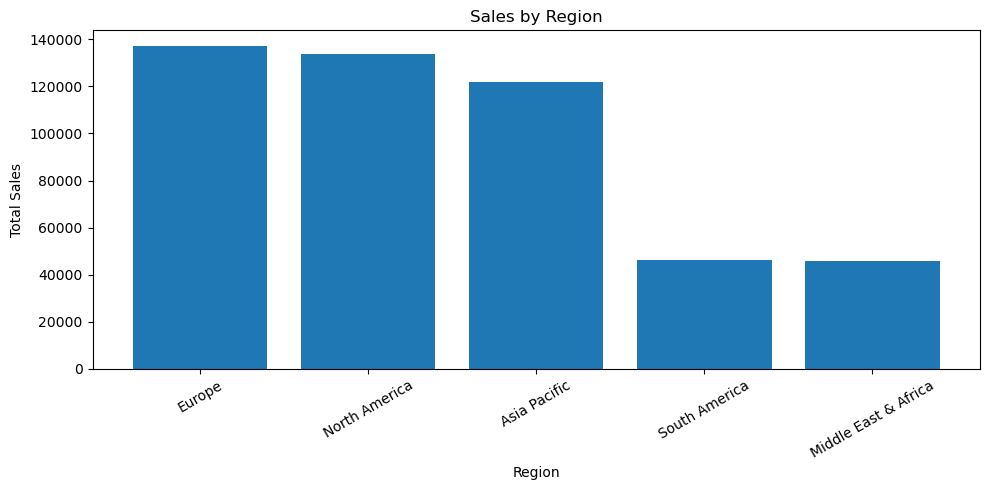

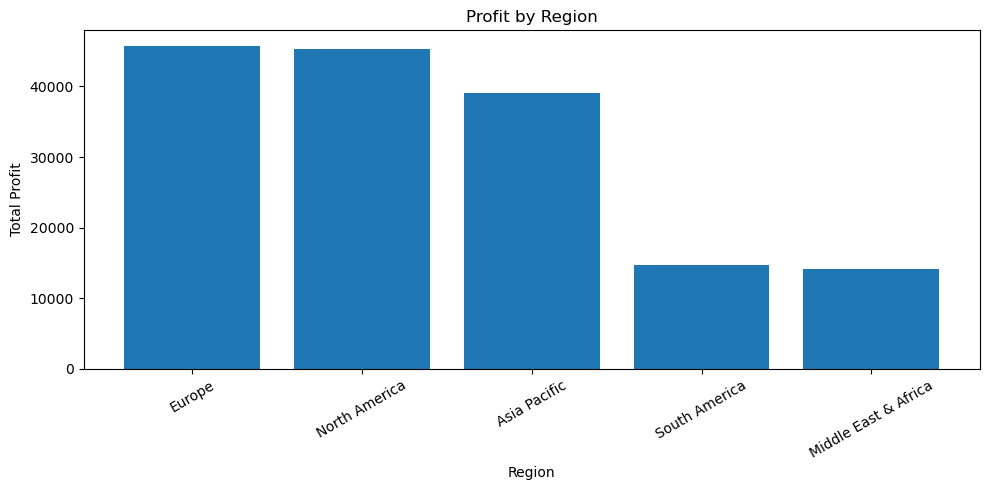

In [17]:
# ==========================================
# REGIONAL PERFORMANCE ANALYSIS
# ==========================================

regional_performance = df.groupby('Region').agg(
    Total_Sales=('Total_Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Total_Quantity=('Quantity', 'sum'),
    Number_of_Orders=('Order_ID', 'count')
).reset_index()

# Calculate Profit Margin
regional_performance['Profit_Margin_%'] = (
    regional_performance['Total_Profit']
    / regional_performance['Total_Sales']
) * 100

# Sort by Total Sales
regional_performance = regional_performance.sort_values(
    by='Total_Sales',
    ascending=False
)

display(regional_performance)

# Sales by Region
plt.figure(figsize=(10, 5))
plt.bar(
    regional_performance['Region'],
    regional_performance['Total_Sales']
)
plt.title('Sales by Region')
plt.xlabel('Region')
plt.ylabel('Total Sales')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Profit by Region
plt.figure(figsize=(10, 5))
plt.bar(
    regional_performance['Region'],
    regional_performance['Total_Profit']
)
plt.title('Profit by Region')
plt.xlabel('Region')
plt.ylabel('Total Profit')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

,Discount_Percent,Total_Sales,Total_Profit,Number_of_Orders,Profit_Margin_%
0,0,"130,966.22","50,705.28",503,38.72
1,5,"130,452.23","46,129.15",488,35.36
2,10,"103,136.11","32,932.51",443,31.93
3,15,"61,074.44","16,503.10",312,27.02
4,20,"40,229.76","9,305.38",169,23.13
5,25,"13,272.27","2,568.58",67,19.35
6,30,"5,428.31",728.32,18,13.42


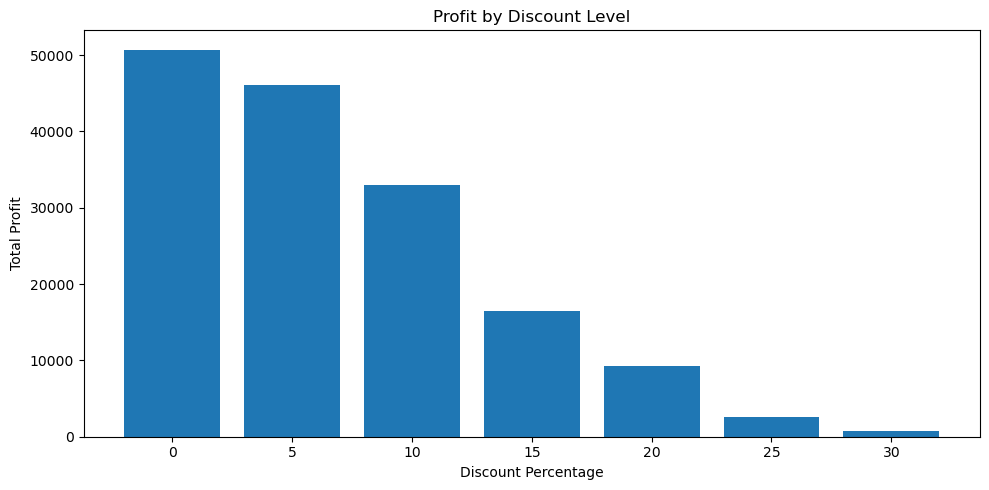

Loss-Making Orders: 272
Total Loss: -953.39


,Order_ID,Product_Category,Customer_Segment,Discount_Percent,Total_Sales,Profit
314,ORD-10024,Office Supplies,Consumer,0,6.62,-11.28
1179,ORD-11269,Office Supplies,Corporate,15,4.14,-10.48
1387,ORD-11001,Office Supplies,Corporate,20,2.42,-10.10
53,ORD-11430,Office Supplies,Home Office,10,4.30,-9.69
1544,ORD-11873,Office Supplies,Corporate,10,6.24,-9.17
...,...,...,...,...,...,...
692,ORD-10672,Office Supplies,Consumer,15,28.36,-0.08
368,ORD-10842,Clothing & Accessories,Consumer,15,29.04,-0.06
1439,ORD-11862,Furniture,Consumer,20,46.70,-0.04
1908,ORD-10682,Office Supplies,Corporate,5,22.80,-0.01


In [18]:
# ==========================================
# DISCOUNT & PROFIT RISK ANALYSIS
# ==========================================

discount_analysis = df.groupby('Discount_Percent').agg(
    Total_Sales=('Total_Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Number_of_Orders=('Order_ID', 'count')
).reset_index()

discount_analysis['Profit_Margin_%'] = (
    discount_analysis['Total_Profit']
    / discount_analysis['Total_Sales']
) * 100

display(discount_analysis)

# Profit by Discount Level
plt.figure(figsize=(10, 5))
plt.bar(
    discount_analysis['Discount_Percent'].astype(str),
    discount_analysis['Total_Profit']
)
plt.title('Profit by Discount Level')
plt.xlabel('Discount Percentage')
plt.ylabel('Total Profit')
plt.tight_layout()
plt.show()

# Identify loss-making orders
loss_orders = df[df['Profit'] < 0]

print("Loss-Making Orders:", len(loss_orders))
print("Total Loss:", round(loss_orders['Profit'].sum(), 2))

display(
    loss_orders[
        [
            'Order_ID',
            'Product_Category',
            'Customer_Segment',
            'Discount_Percent',
            'Total_Sales',
            'Profit'
        ]
    ].sort_values('Profit')
)


TOP 10 PRODUCTS BY SALES


,Product_Name,Total_Sales,Total_Profit,Total_Quantity,Number_of_Orders,Profit_Margin_%
28,Standing Desk Converter,"46,614.22","14,694.35",215,57,31.52
9,Ergonomic Office Chair,"45,405.15","15,104.58",167,42,33.27
5,Corner L-Shaped Desk,"41,070.48","13,663.00",146,39,33.27
18,Mesh Back Task Chair,"38,179.77","12,820.11",213,59,33.58
37,Wireless Bluetooth Headphones,"28,258.70","10,611.08",212,56,37.55
17,Mechanical Gaming Keyboard,"24,072.42","8,381.19",227,58,34.82
10,Filing Cabinet 3-Drawer,"23,108.01","7,041.80",170,45,30.47
12,Folding Table Portable,"18,663.13","5,589.03",226,57,29.95
23,Portable External SSD 1TB,"18,065.30","6,556.75",185,55,36.29
2,Bookshelf 5-Tier,"17,741.59","5,490.57",154,55,30.95


TOP 10 PRODUCTS BY PROFIT


,Product_Name,Total_Sales,Total_Profit,Total_Quantity,Number_of_Orders,Profit_Margin_%
9,Ergonomic Office Chair,"45,405.15","15,104.58",167,42,33.27
28,Standing Desk Converter,"46,614.22","14,694.35",215,57,31.52
5,Corner L-Shaped Desk,"41,070.48","13,663.00",146,39,33.27
18,Mesh Back Task Chair,"38,179.77","12,820.11",213,59,33.58
37,Wireless Bluetooth Headphones,"28,258.70","10,611.08",212,56,37.55
17,Mechanical Gaming Keyboard,"24,072.42","8,381.19",227,58,34.82
10,Filing Cabinet 3-Drawer,"23,108.01","7,041.80",170,45,30.47
23,Portable External SSD 1TB,"18,065.30","6,556.75",185,55,36.29
3,Business Casual Blazer,"14,327.72","6,004.33",160,40,41.91
20,Noise Cancelling Earbuds,"16,119.60","5,973.01",138,48,37.05


BOTTOM 10 PRODUCTS BY PROFIT


,Product_Name,Total_Sales,Total_Profit,Total_Quantity,Number_of_Orders,Profit_Margin_%
21,Paper Clips Box 500pc,901.89,-79.95,152,45,-8.86
13,Highlighters Neon Pack 6,942.61,-0.37,118,39,-0.04
30,Sticky Notes Multicolor 6-Pack,"1,072.27",61.90,125,39,5.77
1,Binder Clips Assorted 48pc,"1,924.59",214.49,194,58,11.14
0,Ballpoint Pen Pack 12,"1,760.36",254.45,170,50,14.45
36,Whiteboard Markers Set 8,"2,090.67",311.95,177,59,14.92
7,Desk Calendar 2025,"2,481.21",489.92,218,59,19.75
29,Stapler Full-Size,"2,622.15",544.94,211,58,20.78
24,Premium Notebook Set A5,"2,536.17",665.31,166,53,26.23
25,Silk Tie Collection,"2,307.23",667.04,84,27,28.91


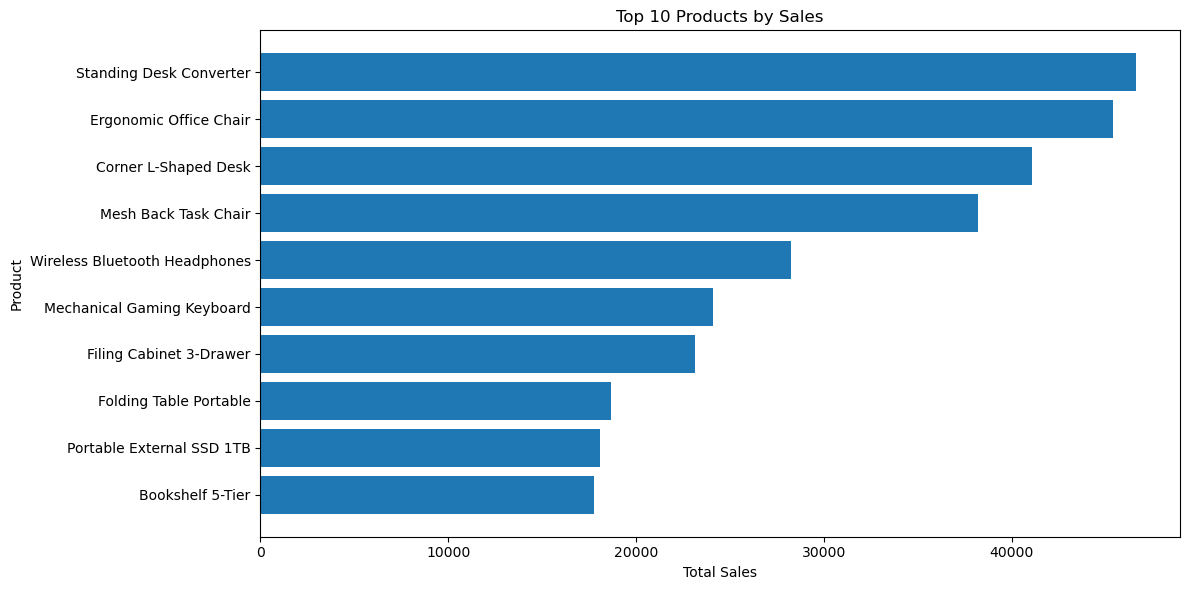

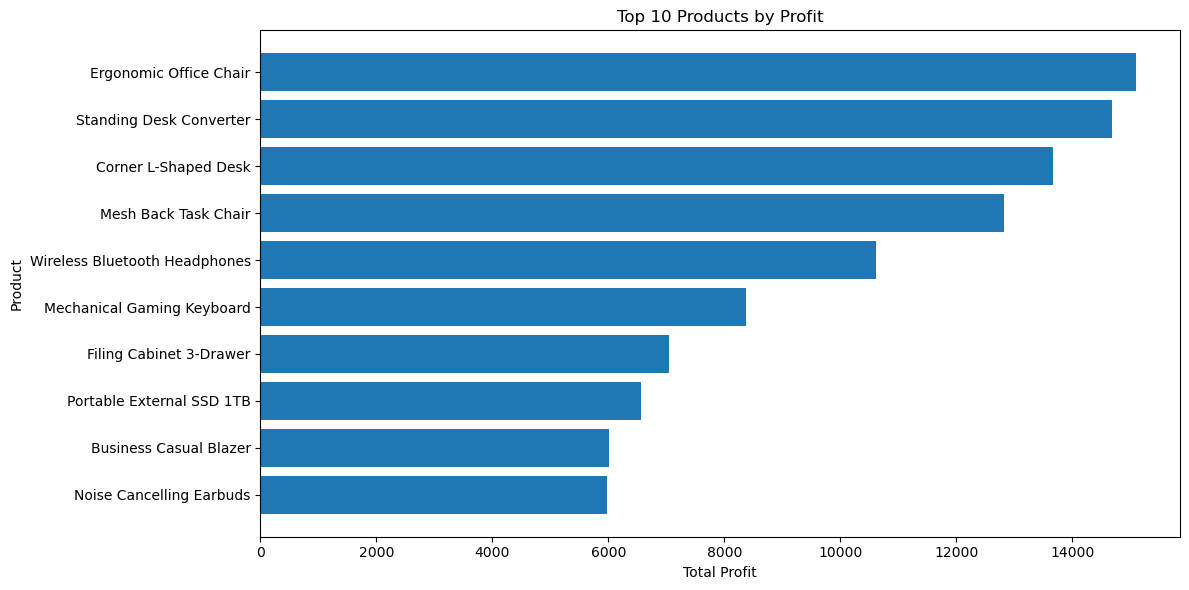

In [19]:
# ==========================================
# TOP & BOTTOM PRODUCT ANALYSIS
# ==========================================

product_performance = df.groupby('Product_Name').agg(
    Total_Sales=('Total_Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Total_Quantity=('Quantity', 'sum'),
    Number_of_Orders=('Order_ID', 'count')
).reset_index()

# Calculate profit margin
product_performance['Profit_Margin_%'] = (
    product_performance['Total_Profit']
    / product_performance['Total_Sales']
) * 100


# ------------------------------------------
# TOP 10 PRODUCTS BY SALES
# ------------------------------------------

top_sales_products = product_performance.sort_values(
    by='Total_Sales',
    ascending=False
).head(10)

print("TOP 10 PRODUCTS BY SALES")
display(top_sales_products)


# ------------------------------------------
# TOP 10 PRODUCTS BY PROFIT
# ------------------------------------------

top_profit_products = product_performance.sort_values(
    by='Total_Profit',
    ascending=False
).head(10)

print("TOP 10 PRODUCTS BY PROFIT")
display(top_profit_products)


# ------------------------------------------
# BOTTOM 10 PRODUCTS BY PROFIT
# ------------------------------------------

bottom_profit_products = product_performance.sort_values(
    by='Total_Profit',
    ascending=True
).head(10)

print("BOTTOM 10 PRODUCTS BY PROFIT")
display(bottom_profit_products)


# ------------------------------------------
# TOP 10 SALES CHART
# ------------------------------------------

plt.figure(figsize=(12, 6))

plt.barh(
    top_sales_products['Product_Name'],
    top_sales_products['Total_Sales']
)

plt.title('Top 10 Products by Sales')
plt.xlabel('Total Sales')
plt.ylabel('Product')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


# ------------------------------------------
# TOP 10 PROFIT CHART
# ------------------------------------------

plt.figure(figsize=(12, 6))

plt.barh(
    top_profit_products['Product_Name'],
    top_profit_products['Total_Profit']
)

plt.title('Top 10 Products by Profit')
plt.xlabel('Total Profit')
plt.ylabel('Product')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [20]:
# ==============================
# EXECUTIVE KPI SUMMARY
# ==============================

total_sales = df['Total_Sales'].sum()
total_profit = df['Profit'].sum()
total_orders = df['Order_ID'].nunique()
total_quantity = df['Quantity'].sum()
total_customers = df['Customer_Name'].nunique()

average_order_value = total_sales / total_orders
profit_margin = (total_profit / total_sales) * 100
average_discount = df['Discount_Percent'].mean()
total_shipping_cost = df['Shipping_Cost'].sum()

print("========== E-COMMERCE BUSINESS KPIs ==========\n")

print(f"Total Sales        : ${total_sales:,.2f}")
print(f"Total Profit       : ${total_profit:,.2f}")
print(f"Total Orders       : {total_orders:,}")
print(f"Total Quantity     : {total_quantity:,}")
print(f"Total Customers    : {total_customers:,}")
print(f"Average Order Value: ${average_order_value:,.2f}")
print(f"Profit Margin      : {profit_margin:.2f}%")
print(f"Average Discount   : {average_discount:.2f}%")
print(f"Shipping Cost      : ${total_shipping_cost:,.2f}")

========== E-COMMERCE BUSINESS KPIs ==========

Total Sales        : $484,559.34
Total Profit       : $158,872.32
Total Orders       : 2,000
Total Quantity     : 7,115
Total Customers    : 1,534
Average Order Value: $242.28
Profit Margin      : 32.79%
Average Discount   : 8.57%
Shipping Cost      : $25,804.24


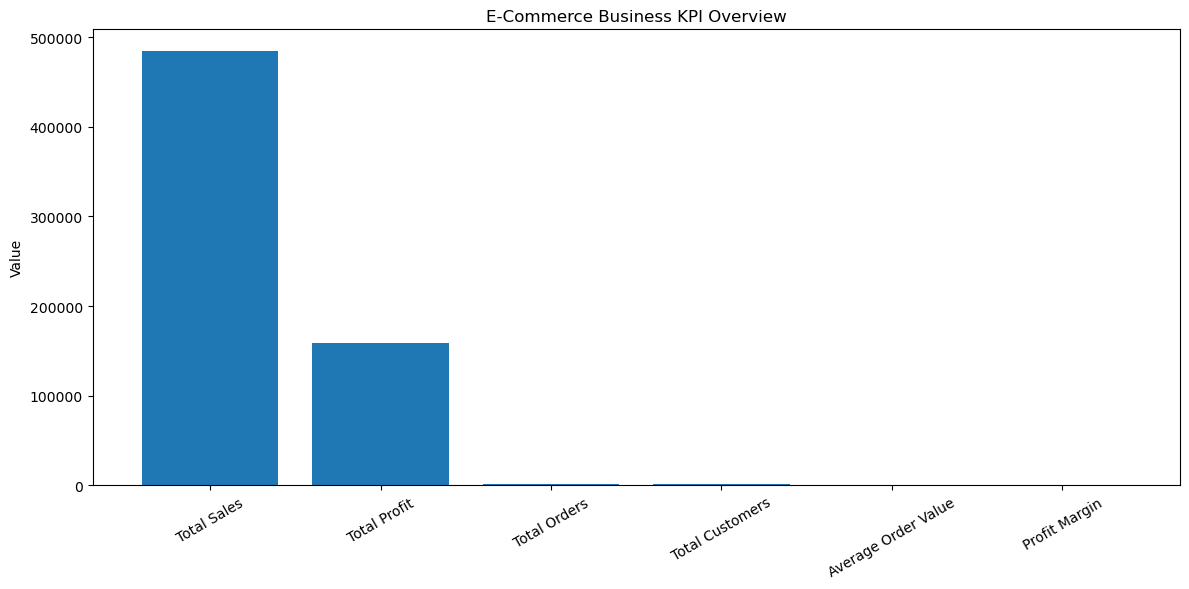

In [21]:
# ==============================
# KPI VISUAL DASHBOARD
# ==============================

kpi_names = [
    'Total Sales',
    'Total Profit',
    'Total Orders',
    'Total Customers',
    'Average Order Value',
    'Profit Margin'
]

kpi_values = [
    total_sales,
    total_profit,
    total_orders,
    total_customers,
    average_order_value,
    profit_margin
]

plt.figure(figsize=(12, 6))

bars = plt.bar(kpi_names, kpi_values)

plt.title('E-Commerce Business KPI Overview')
plt.ylabel('Value')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [22]:
# ==============================
# FINAL BUSINESS INSIGHT SUMMARY
# ==============================

print("========== BUSINESS INSIGHTS ==========\n")

print("1. SALES & PROFIT")
print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Overall Profit Margin: {profit_margin:.2f}%")

print("\n2. CUSTOMER & ORDER PERFORMANCE")
print(f"Total Orders: {total_orders:,}")
print(f"Total Customers: {total_customers:,}")
print(f"Average Order Value: ${average_order_value:,.2f}")

print("\n3. DISCOUNT & COST")
print(f"Average Discount: {average_discount:.2f}%")
print(f"Total Shipping Cost: ${total_shipping_cost:,.2f}")

print("\n4. BUSINESS RECOMMENDATIONS")
print("- Focus on high-performing product categories.")
print("- Investigate low-profit product categories and products.")
print("- Monitor discount levels to protect profit margins.")
print("- Identify high-value customer segments for targeted marketing.")
print("- Focus on regions with strong sales and profitability.")
print("- Review loss-making orders and their underlying causes.")

========== BUSINESS INSIGHTS ==========

1. SALES & PROFIT
Total Sales: $484,559.34
Total Profit: $158,872.32
Overall Profit Margin: 32.79%

2. CUSTOMER & ORDER PERFORMANCE
Total Orders: 2,000
Total Customers: 1,534
Average Order Value: $242.28

3. DISCOUNT & COST
Average Discount: 8.57%
Total Shipping Cost: $25,804.24

4. BUSINESS RECOMMENDATIONS
- Focus on high-performing product categories.
- Investigate low-profit product categories and products.
- Monitor discount levels to protect profit margins.
- Identify high-value customer segments for targeted marketing.
- Focus on regions with strong sales and profitability.
- Review loss-making orders and their underlying causes.
